<img src="img/ost_logo.png" width="240" align="right"/>
<div style="text-align: left"> <b> Machine Learning Projekt</b> <br> HS 2025 <br> <a href="mailto:ryan.mikus@ost.ch"> Ryan Mikus </a> und <a href="mailto:ilija.amato@ost.ch"> Ilija Amato </a> </div>

<ul style="list-style:none;padding-left:0;margin:0">
  <li><a href="01_Einleitung.ipynb">1. Einleitung</a></li>
  <li><a href="02_Datensammlung.ipynb">2. Datensammlung</a></li>
  <li><a href="03_Preprocessing.ipynb">3. Preprocessing</a></li>
  <li><a href="04_Explorative_Datenanalyse.ipynb">4. Explorative Datenanalyse</a></li>
  <li><strong>5. Modellierung</strong></li>
  <li><a href="06_Backtest.ipynb">6. Backtest &amp; Performance</a></li>
  <li><a href="07_Fazit.ipynb">7. Fazit</a></li>
</ul>

<h1 id="5">5. Modellierung</h1>

In diesem Abschnitt wird auf Basis der zuvor analysierten Marktdaten ein ML-basierter Modellierungsprozess für ein Pairs-Trading-Setup umgesetzt. Ziel ist es, die zukünftige Spread-Bewegung über einen festen Horizont vorherzusagen und verschiedene Modellarchitekturen unter zeitlich konsistenten Bedingungen zu vergleichen.

Der Fokus liegt auf der praktischen Umsetzung, der Vergleichbarkeit der Modelle sowie der Analyse der resultierenden Outputs. Die Evaluation erfolgt mittels Walk-Forward-Ansatz und wird durch Performance- und Diagnosemetriken ergänzt.

<img src="img/ml_pipeline.png" width="240" style="display:block; margin-left:auto; margin-right:auto;"/>

Die Abbildung zeigt den Ablauf der verwendeten ML-Pipeline – von den Marktdaten über Feature-Engineering und Modellierung bis hin zur Performance- und Trading-Inspektion.

In diesem Kapitel werden folgende Schritte behandelt:

- [Projektspezifisches Preprocessing](#51)
- [Modellarchitekturen](#52)
- [Hyperparameter-Tuning](#53)
- [Walk-Forward Evaluation](#54)
- [Modellperformance und Vergleich](#55)
- [Trading-Inspektion](#56)
- [Export für Backtest](#57)

In [1]:
# Zelle 1: Imports & Konfiguration
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score
from sklearn.base import clone

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from xgboost import XGBClassifier

from pairs_trading import data_io as io
from pairs_trading import modeling


# Dateninput
DATA_DIR = "data"
BASENAME = "market_data_cleaned"

# Zeitraum
# Es braucht mindestens:
# LOOKBACK_PAIRS_DAYS + LOOKBACK_TRAIN_DAYS + 1
# Tage im Dataset, damit es funktioniert. Das 1 ist der Testtag.
START_DATE = "earliest"
END_DATE = "latest"

# Walk-forward Fenster (Handelstage)
LOOKBACK_PAIR_DAYS = 10      # Lookback für Pair-Selektion (Korrelation + Cointegration)
LOOKBACK_TRAIN_DAYS = 10     # Rolling Train-Window für ML-Fit

# Pair-Selektion
TOP_CORR_PAIRS = 50          # Top-N Paare nach |corr| (Candidate-Set)
TOP_DAILY_PAIRS = 5          # Top-N Paare nach Cointegration-Consistency
P_COINTEGRATION = 0.05       # p-Value Schwelle für "signifikant" pro Tag

# Rebalance / Cache
REBALANCE_EVERY_N_DAYS = 5   # Paare nur alle N Handelstage neu bestimmen
CACHE_DIR = "cache_pairs"

# Reproduzierbarkeit / Parallelisierung
RANDOM_STATE = 42
N_JOBS = -1

# Horizon k
K_FIXED = 5
best_k = K_FIXED # könnte noch optimiert werden

# Feature Parameter
RSI_W = 14
Z_W = 60
VOL_W = 20

# XGB Hyperparameter Tuning
TUNE_XGB_LR = True          # True = tuning ausführen, False = fixen Wert nutzen
XGB_LR_CANDIDATES = [0.001, 0.005, 0.01, 0.02]
XGB_LR_BEST = 0.01           # hier manuell setzen oder automatisch überschreiben

In [2]:
# Zelle 2: Gesäuberte Daten laden
df = io.load_preprocessed_data(
    data_dir=DATA_DIR,
    basename=BASENAME
)


[Preprocessed Data Load]
Pfad: data/market_data_cleaned.parquet

[Preprocessed Data]
Shape: (29604189, 7)
Spalten: ['symbol', 'datetime', 'open', 'high', 'low', 'volume', 'close_filled']

Head:
  symbol                  datetime        open        high         low  \
0      A 2025-11-07 14:30:00+00:00  146.520004  147.119995  145.729996   
1      A 2025-11-07 14:31:00+00:00         NaN         NaN         NaN   
2      A 2025-11-07 14:32:00+00:00  146.089996  146.089996  146.089996   
3      A 2025-11-07 14:33:00+00:00         NaN         NaN         NaN   
4      A 2025-11-07 14:34:00+00:00  146.049698  146.049698  146.049698   

    volume  close_filled  
0  13361.0    145.729996  
1      NaN    145.909996  
2    427.0    146.089996  
3      NaN    146.069847  
4   1387.0    146.049698  


<h2 id="51">5.1. Projektspezifisches Preprocessing</h2>

Wie bereits erwähnt, wird für dieses Projekt nur die Spalte `close_filled` verwendet. Die Daten werden wieder in das Wide-Format transformiert und logarithmiert.

In [3]:
# Zelle 3: Unnötige Spalten droppen
df = df[["datetime", "symbol", "close_filled"]].copy()
df.head()

,datetime,symbol,close_filled
0,2025-11-07 14:30:00+00:00,A,145.729996
1,2025-11-07 14:31:00+00:00,A,145.909996
2,2025-11-07 14:32:00+00:00,A,146.089996
3,2025-11-07 14:33:00+00:00,A,146.069847
4,2025-11-07 14:34:00+00:00,A,146.049698


In [4]:
# Zelle 4: Zeitraum definieren
df = df.copy()
df["datetime"] = pd.to_datetime(df["datetime"], utc=True, errors="coerce")

if START_DATE == "earliest":
    start_ts = df["datetime"].min()
else:
    start_ts = pd.to_datetime(START_DATE, utc=True)

if END_DATE == "latest":
    end_ts = df["datetime"].max()
else:
    end_ts = pd.to_datetime(END_DATE, utc=True)

df = df[(df["datetime"] >= start_ts) & (df["datetime"] <= end_ts)]

print(
    "Data range after slicing:",
    df["datetime"].min(),
    "->",
    df["datetime"].max(),
)

Data range after slicing: 2025-11-07 14:30:00+00:00 -> 2026-07-17 20:00:00+00:00


In [5]:
# Zelle 5: Long -> Wide
df = df.copy()
df["datetime"] = pd.to_datetime(df["datetime"], utc=True, errors="coerce")
df = df.dropna(subset=["datetime", "symbol", "close_filled"]).sort_values(["datetime", "symbol"])

prices_wide = (
    df.pivot(index="datetime", columns="symbol", values="close_filled")
    .sort_index()
)

print("prices_wide shape:", prices_wide.shape)
print("date range:", prices_wide.index.min(), "->", prices_wide.index.max())

prices_wide shape: (65643, 451)
date range: 2025-11-07 14:30:00+00:00 -> 2026-07-17 20:00:00+00:00


Für die nachfolgenden Schritte (Pair-Selektion, Feature-Berechnung und Walk-Forward) wird das Wide-Format als zweckmäßige Arbeitsrepräsentation verwendet, auch wenn es nicht dem Tidy-Data-Prinzip entspricht.

In [6]:
# Zelle 6: Log-Preise (Input für Cointegration/Features)
log_prices = np.log(prices_wide).dropna(how="all")
print("log_prices shape:", log_prices.shape)

log_prices shape: (65643, 451)


In [7]:
# Zelle 7: Handelstage & Walk-forward Setup
all_days = pd.Index(log_prices.index.normalize().unique()).sort_values()
print("n_days:", len(all_days), "| first:", all_days.min().date(), "| last:", all_days.max().date())

min_required = max(LOOKBACK_PAIR_DAYS, LOOKBACK_TRAIN_DAYS)
test_days = all_days[min_required:]
print("walk-forward test days:", len(test_days))

n_days: 168 | first: 2025-11-07 | last: 2026-07-17
walk-forward test days: 158


<h2 id="52">5.2. Modellarchitekturen</h2>

Zur Vorhersage der Spread-Bewegung werden mehrere Machine-Learning-Modelle mit unterschiedlicher Modellkomplexität eingesetzt. Ziel ist ein robuster Vergleich linearer, baumbasierter und ensemblebasierter Ansätze unter identischen Daten- und Evaluationsbedingungen.

Neben einer logistischen Regression als lineare Baseline kommen ein Random-Forest-Classifier sowie ein Gradient-Boosting-Modell (XGBoost) zum Einsatz. Ergänzend wird ein Soft-Voting-Ensemble verwendet, das die probabilistischen Outputs aller Einzelmodelle kombiniert, um Stabilität und Robustheit der Vorhersagen zu erhöhen.

Alle Modelle werden in einer einheitlichen Pipeline definiert und ausschließlich im Rahmen des Walk-Forward-Prozesses trainiert und evaluiert, um zeitliches Leckage zu vermeiden und eine realistische Performanceabschätzung zu gewährleisten.

In [8]:
# Zelle 8: Modelle definieren
logreg = Pipeline([
    ("clf", LogisticRegression(
        max_iter=2000,
        solver="lbfgs",
        random_state=RANDOM_STATE,
    ))
])

rf = Pipeline([
    ("clf", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=10,
        n_jobs=N_JOBS,
        random_state=RANDOM_STATE,
        class_weight="balanced_subsample",
    ))
])

xgb = Pipeline([
    ("clf", XGBClassifier(
        n_estimators=400,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=RANDOM_STATE,
        n_jobs=0,
        eval_metric="logloss",
        tree_method="hist",
    ))
])

vote_soft = VotingClassifier(
    estimators=[
        ("lr", clone(logreg)),
        ("rf", clone(rf)),
        ("xgb", clone(xgb)),
    ],
    voting="soft",
    n_jobs=N_JOBS,
)

models = {
    "LogReg": logreg,
    "RF": rf,
    "XGB": xgb,
    "VoteSoft": vote_soft,
}

<h2 id="53">5.3. Hyperparameter-Tuning</h2>

Zur Begrenzung der Rechenkomplexität wird das Hyperparameter-Tuning gezielt auf die Lernrate des XGBoost-Modells beschränkt. Diese Entscheidung erlaubt einen kontrollierten Vergleich, ohne den Walk-Forward-Prozess durch umfangreiche Grid- oder Random-Search-Verfahren zu verzerren.

Die Bewertung erfolgt mittels walk-forward-basierter Evaluation auf Basis der mittleren AUC über alle Testtage. Der Hyperparameter mit der besten durchschnittlichen Performance wird anschließend fixiert und im finalen Modellvergleich verwendet.

<h3 id="531">5.3.1. Tuning-/Holdout-Split</h3>

Das Hyperparameter-Tuning weiter unten wählt die Lernrate anhand der mittleren AUC über die Testtage. Würde dieselbe Menge an Tagen anschliessend auch für die berichtete Performance verwendet, wäre das Ergebnis optimistisch verzerrt (Data Snooping): die Lernrate wird ja genau darauf optimiert, auf diesen Tagen gut abzuschneiden.

Um das zu vermeiden, werden die Testtage chronologisch in zwei Blöcke geteilt:
- **Tuning-Block** (alle Tage ausser den letzten `HOLDOUT_DAYS`): wird für die Lernraten-Wahl unten verwendet.
- **Holdout-Block** (letzte `HOLDOUT_DAYS` Tage): wird nie für Tuning-Entscheidungen verwendet und liefert die "ehrliche" Performance-Zahl. Der volle Testzeitraum (`test_days`) wird weiterhin für die durchgehenden Zeitreihen-Plots in Abschnitt 5.4 verwendet, damit diese nicht an der Schnittstelle abbrechen, aber die separat berichtete Kennzahl am Ende von 5.4 bezieht sich ausschliesslich auf den Holdout-Block.

**Verkürzung des Tuning-Blocks auf die jüngsten `TUNING_DAYS_N` Tage:** Für das Lernraten-Tuning wird nicht der gesamte Tuning-Block verwendet (dessen Länge mit wachsendem Datensatz zunimmt, siehe Ausgabe unten), sondern nur dessen jüngste `TUNING_DAYS_N` Tage. Das Tuning-Raster (`XGB_LR_CANDIDATES`) besteht aus nur wenigen grob gestaffelten Kandidaten über eine Grössenordnung hinweg. Die Tag-zu-Tag-Streuung der AUC ist gross genug, dass der Standardfehler des Mittelwerts bereits bei `TUNING_DAYS_N` Tagen deutlich kleiner bleibt als die zu erwartenden AUC-Unterschiede zwischen so weit auseinanderliegenden Lernraten; eine Verwendung des gesamten (grösseren) Tuning-Blocks würde diesen Vorteil nicht wesentlich vergrössern, aber die Laufzeit des Sweeps deutlich erhöhen. `TUNING_DAYS_N` Tage reichen also aus, um die beste Lernrate zuverlässig zu bestimmen. Es werden bewusst die **jüngsten** Tage des Tuning-Blocks verwendet (direkt angrenzend an den Holdout-Block), damit Tuning- und Holdout-Zeitraum ein ähnliches Marktregime abdecken. Die älteren Tage des Tuning-Blocks (`tuning_days_full` minus `tuning_days`) bleiben dadurch ungenutzt, statt eine Lücke mitten in der Zeitreihe zu erzeugen.


In [9]:
# Zelle 8b: Tuning-/Holdout-Split
HOLDOUT_DAYS = 40
TUNING_DAYS_N = 50  # nur die juengsten N Tage des Tuning-Blocks werden fuers LR-Tuning verwendet

tuning_days_full = test_days[:-HOLDOUT_DAYS]
tuning_days = tuning_days_full[-TUNING_DAYS_N:]
holdout_days = test_days[-HOLDOUT_DAYS:]

print(f"test_days total:       {len(test_days)}")
print(f"tuning_days_full:       {len(tuning_days_full)}  ({tuning_days_full.min().date()} -> {tuning_days_full.max().date()})")
print(f"tuning_days (verwendet): {len(tuning_days)}  ({tuning_days.min().date()} -> {tuning_days.max().date()})")
print(f"holdout_days:           {len(holdout_days)}  ({holdout_days.min().date()} -> {holdout_days.max().date()})")

test_days total:       158
tuning_days_full:       118  (2025-11-21 -> 2026-05-19)
tuning_days (verwendet): 50  (2026-03-10 -> 2026-05-19)
holdout_days:           40  (2026-05-20 -> 2026-07-17)


In [10]:
# Zelle 9: Hyperparameter-Tuning (XGB learning_rate)
if TUNE_XGB_LR:
    print("Tuning XGB learning_rate...")

    lr_results = []

    for lr in XGB_LR_CANDIDATES:
        print(f"   testing learning_rate = {lr}")

        # Modell mit neuer LR setzen
        models["XGB"].named_steps["clf"].set_params(learning_rate=lr)

        scores = modeling.walk_forward_run(
            k=best_k,
            models={"XGB": models["XGB"]},
            log_prices=log_prices,
            all_days=all_days,
            test_days=tuning_days,
            lookback_train_days=LOOKBACK_TRAIN_DAYS,
            lookback_pair_days=LOOKBACK_PAIR_DAYS,
            top_corr_pairs=TOP_CORR_PAIRS,
            top_daily_pairs=TOP_DAILY_PAIRS,
            p_cointegration=P_COINTEGRATION,
            rebalance_every_n_days=REBALANCE_EVERY_N_DAYS,
            cache_dir=CACHE_DIR,
            rsi_w=RSI_W,
            z_w=Z_W,
            vol_w=VOL_W,
            min_train_samples=200,
            min_test_samples=50,
            verbose=False,
        )

        mean_auc = scores["auc"].mean()
        lr_results.append((lr, mean_auc))

        print(f"      mean AUC = {mean_auc:.4f}")

    # best LR bestimmen
    XGB_LR_BEST, best_auc = max(lr_results, key=lambda x: x[1])

    print(f"\nBest learning_rate = {XGB_LR_BEST} (mean AUC = {best_auc:.4f}, nur Tuning-Block)")

# finalen Wert setzen (immer!)
models["XGB"].named_steps["clf"].set_params(learning_rate=XGB_LR_BEST)

Tuning XGB learning_rate...
   testing learning_rate = 0.001
      mean AUC = 0.7439
   testing learning_rate = 0.005
      mean AUC = 0.7464
   testing learning_rate = 0.01
      mean AUC = 0.7467
   testing learning_rate = 0.02
      mean AUC = 0.7456

Best learning_rate = 0.01 (mean AUC = 0.7467, nur Tuning-Block)


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


<h2 id="54">5.4. Walk-Forward Evaluation</h2>

Die Modellbewertung erfolgt mittels eines rollierenden Walk-Forward-Ansatzes, bei dem für jeden Handelstag ein neues Modell auf einem festen historischen Fenster trainiert und auf dem unmittelbar folgenden Testzeitpunkt evaluiert wird. Dieses Vorgehen stellt eine strikt zeitlich konsistente Evaluation sicher und vermeidet Informationsleckagen.

Als primäre Bewertungsmetrik wird die Area Under the ROC Curve (AUC) verwendet, da sie unabhängig von einem festen Klassifikationsschwellenwert ist und die Trennschärfe der Modelle über alle Entscheidungsgrenzen hinweg abbildet. Dies ist insbesondere für probabilistische Handelssignale vorteilhaft, bei denen der finale Schwellenwert erst in einem späteren Schritt festgelegt wird.

Die Modellierung erfolgt als binäres Klassifikationsproblem. Die Zielvariable beschreibt, ob sich der Spread über den Prognosehorizont \(k\) in die erwartete Richtung bewegt (Label = 1) oder nicht (Label = 0). Die Modelle liefern entsprechend probabilistische Vorhersagen für das Eintreten der positiven Klasse.

Auf eine klassische kreuzvalidierte Performance-Evaluation (z. B. k-fold Cross-Validation) wird bewusst verzichtet, da diese die zeitliche Struktur der Daten aufbrechen würde. Der verwendete Walk-Forward-Ansatz stellt sicher, dass Trainings- und Testdaten strikt chronologisch getrennt sind und die Evaluation dem realen Einsatzszenario entspricht.

In [11]:
# Zelle 10: Walk-forward Run
final_scores = modeling.walk_forward_run(
    k=best_k,
    models=models,
    log_prices=log_prices,
    all_days=all_days,
    test_days=test_days,
    lookback_train_days=LOOKBACK_TRAIN_DAYS,
    lookback_pair_days=LOOKBACK_PAIR_DAYS,
    top_corr_pairs=TOP_CORR_PAIRS,
    top_daily_pairs=TOP_DAILY_PAIRS,
    p_cointegration=P_COINTEGRATION,
    rebalance_every_n_days=REBALANCE_EVERY_N_DAYS,
    cache_dir=CACHE_DIR,
    rsi_w=RSI_W,
    z_w=Z_W,
    vol_w=VOL_W,
    min_train_samples=200,
    min_test_samples=50,
    verbose=True,
)

display(final_scores.head())

final_summary = (
    final_scores.groupby("model")["auc"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
)
display(final_summary)

2025-11-21 | best_auc=0.729
2025-11-24 | best_auc=0.726
2025-11-25 | best_auc=0.742
2025-11-26 | best_auc=0.763
2025-12-01 | best_auc=0.740
2025-12-02 | best_auc=0.755
2025-12-03 | best_auc=0.738
2025-12-04 | best_auc=0.771
2025-12-05 | best_auc=0.730
2025-12-08 | best_auc=0.726
2025-12-09 | best_auc=0.744
2025-12-10 | best_auc=0.723
2025-12-11 | best_auc=0.743
2025-12-12 | best_auc=0.745
2025-12-15 | best_auc=0.741
2025-12-16 | best_auc=0.742
2025-12-17 | best_auc=0.739
2025-12-18 | best_auc=0.767
2025-12-19 | best_auc=0.749
2025-12-22 | best_auc=0.749
2025-12-23 | best_auc=0.762
2025-12-26 | best_auc=0.764
2025-12-29 | best_auc=0.775
2025-12-30 | best_auc=0.753
2025-12-31 | best_auc=0.770
2026-01-02 | best_auc=0.737
2026-01-05 | best_auc=0.745
2026-01-07 | best_auc=0.752
2026-01-08 | best_auc=0.749
2026-01-09 | best_auc=0.737
2026-01-12 | best_auc=0.725
2026-01-13 | best_auc=0.752
2026-01-14 | best_auc=0.710
2026-01-15 | best_auc=0.745
2026-01-16 | best_auc=0.744
2026-01-21 | best_au

,day,model,auc,n_pairs,n_train,n_test
0,2025-11-21 00:00:00+00:00,LogReg,0.492379,5,19005,1930
1,2025-11-21 00:00:00+00:00,RF,0.727742,5,19005,1930
2,2025-11-21 00:00:00+00:00,XGB,0.728825,5,19005,1930
3,2025-11-21 00:00:00+00:00,VoteSoft,0.727742,5,19005,1930
4,2025-11-24 00:00:00+00:00,LogReg,0.511620,5,19005,1930


,mean,std
model,,
XGB,0.745718,0.014138
VoteSoft,0.739336,0.014428
RF,0.734763,0.014075
LogReg,0.498097,0.023577


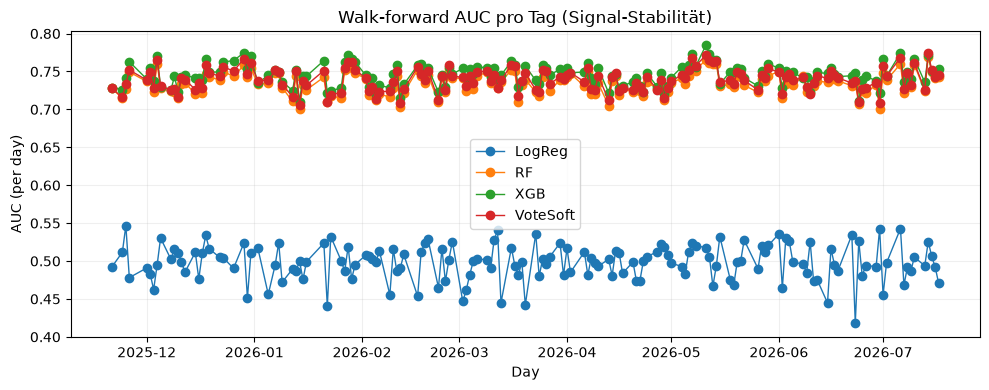

In [12]:
# Zelle 11: AUC pro Tag (Signal-Stabilität)
modeling.plot_auc_per_day(final_scores)

Die aggregierten AUC-Ergebnisse zeigen, dass nichtlineare und ensemblebasierte Modelle die lineare Baseline deutlich übertreffen. XGBoost erzielt die höchste durchschnittliche AUC bei geringer Varianz über die Walk-Forward-Perioden und wird daher in den folgenden Analysen als Referenzmodell verwendet. Die AUC-Verläufe über die Zeit weisen insgesamt auf eine robuste, tagesübergreifend stabile Modellgüte hin.

<h3 id="541">5.4.1. Holdout-Auswertung (ohne Data Snooping)</h3>

Die obige Zusammenfassung mittelt über **alle** Testtage, einschliesslich der `tuning_days`, auf denen die XGB-Lernrate ausgewählt wurde. Das ist nützlich für den durchgehenden Verlauf, aber als Bewertung der Modellgüte optimistisch verzerrt. Die folgende Zahl beschränkt sich auf den nie für Tuning verwendeten `holdout_days`-Block und ist die Zahl, die in einer Bewerbung/Publikation zitiert werden sollte.

In [13]:
# Zelle 10b: Holdout-only Auswertung
holdout_scores = final_scores[final_scores["day"].isin(holdout_days)]

holdout_summary = (
    holdout_scores.groupby("model")["auc"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
)
print(f"Holdout-Zeitraum: {holdout_days.min().date()} -> {holdout_days.max().date()} ({len(holdout_days)} Tage)")
display(holdout_summary)

Holdout-Zeitraum: 2026-05-20 -> 2026-07-17 (40 Tage)


,mean,std
model,,
XGB,0.745713,0.012761
VoteSoft,0.740176,0.013818
RF,0.735818,0.013716
LogReg,0.498676,0.027379


<h2 id="55">5.5. Modellperformance</h2>

In diesem Abschnitt wird die Performance der Modelle anhand aggregierter Metriken sowie diagnostischer Visualisierungen analysiert. Neben der durchschnittlichen Vorhersagegüte werden insbesondere Stabilität, Robustheit und Entscheidungscharakteristika der Modelle betrachtet.

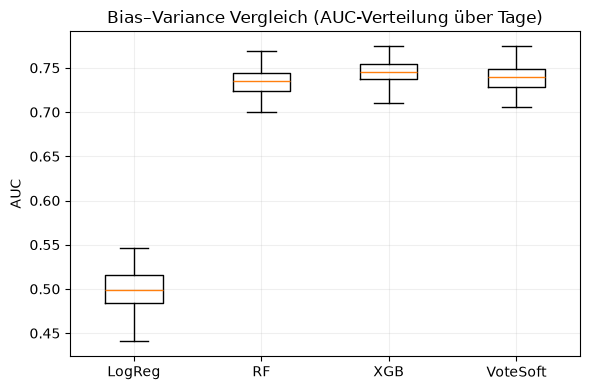

In [14]:
# Zelle 12: Bias–Variance Vergleich (AUC-Verteilung)
modeling.plot_auc_boxplot(final_scores)

Der Bias–Variance-Vergleich zeigt, dass die logistische Regression eine deutlich geringere Trennschärfe und höhere Varianz aufweist. Die baumbasierten Modelle liefern konsistent höhere AUC-Werte, wobei XGBoost und das Soft-Voting-Ensemble sowohl eine hohe Median-Performance als auch eine geringe Streuung über die Tage zeigen.

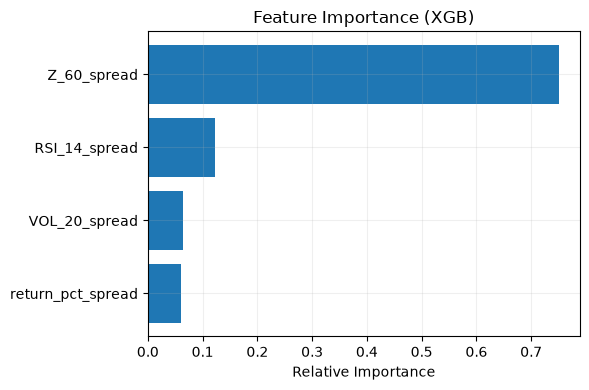

,feature,importance
0,return_pct_spread,0.061234
1,VOL_20_spread,0.063997
2,RSI_14_spread,0.123194
3,Z_60_spread,0.751575


In [15]:
# Zelle 13: Feature Importance (XGB)
xgb_clf = models["XGB"].named_steps["clf"]

feature_names = [
    f"RSI_{RSI_W}_spread",
    f"Z_{Z_W}_spread",
    f"VOL_{VOL_W}_spread",
    "return_pct_spread",
]

imp_df = modeling.plot_xgb_feature_importance(
    feature_importances=xgb_clf.feature_importances_,
    feature_names=feature_names,
)
display(imp_df)

Die Feature-Importance-Analyse des XGBoost-Modells zeigt, dass der Z-Score des Spreads den dominierenden Einfluss auf die Modellentscheidung besitzt. Technische Indikatoren wie RSI und Volatilität liefern ergänzende Informationen, während kurzfristige Renditeänderungen eine untergeordnete Rolle spielen.

Im Vergleich zu einer früheren Konfiguration ohne Learning-Rate-Tuning verschob sich die Gewichtung stärker in Richtung Z-Score, was auf eine veränderte Modellnutzung der Feature-Signale durch die optimierte Parametrisierung hinweist.

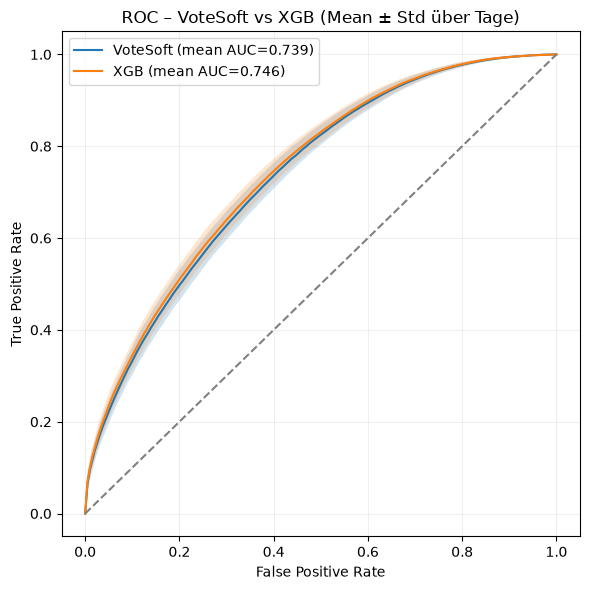

In [16]:
# Zelle 14: ROC – VoteSoft vs XGB
roc_vote = modeling.roc_mean_std_band(
    model_name="VoteSoft",
    k=best_k,
    models=models,
    log_prices=log_prices,
    all_days=all_days,
    test_days=test_days,
    lookback_train_days=LOOKBACK_TRAIN_DAYS,
    lookback_pair_days=LOOKBACK_PAIR_DAYS,
    top_corr_pairs=TOP_CORR_PAIRS,
    top_daily_pairs=TOP_DAILY_PAIRS,
    p_cointegration=P_COINTEGRATION,
    rebalance_every_n_days=REBALANCE_EVERY_N_DAYS,
    cache_dir=CACHE_DIR,
    rsi_w=RSI_W,
    z_w=Z_W,
    vol_w=VOL_W,
    min_train_samples=200,
    min_test_samples=50,
)

roc_xgb = modeling.roc_mean_std_band(
    model_name="XGB",
    k=best_k,
    models=models,
    log_prices=log_prices,
    all_days=all_days,
    test_days=test_days,
    lookback_train_days=LOOKBACK_TRAIN_DAYS,
    lookback_pair_days=LOOKBACK_PAIR_DAYS,
    top_corr_pairs=TOP_CORR_PAIRS,
    top_daily_pairs=TOP_DAILY_PAIRS,
    p_cointegration=P_COINTEGRATION,
    rebalance_every_n_days=REBALANCE_EVERY_N_DAYS,
    cache_dir=CACHE_DIR,
    rsi_w=RSI_W,
    z_w=Z_W,
    vol_w=VOL_W,
    min_train_samples=200,
    min_test_samples=50,
)

modeling.plot_roc_mean_std_comparison(
    roc_a=roc_vote,
    roc_b=roc_xgb,
    label_a="VoteSoft",
    label_b="XGB",
    title="ROC – VoteSoft vs XGB (Mean ± Std über Tage)",
)

Die gemittelten ROC-Kurven zeigen für beide Modelle eine hohe und stabile Trennschärfe über alle Schwellenwerte hinweg. XGBoost erreicht dabei eine leicht höhere durchschnittliche AUC, während das Voting-Ensemble eine vergleichbare, konsistente Performance liefert.

Hier ist zu bemerken, dass XGBoost vor dem Hyperparameter-Tuning eine leicht tiefere durchschnittliche AUC lieferte (im Vergleich zum Voting-Ensemble).

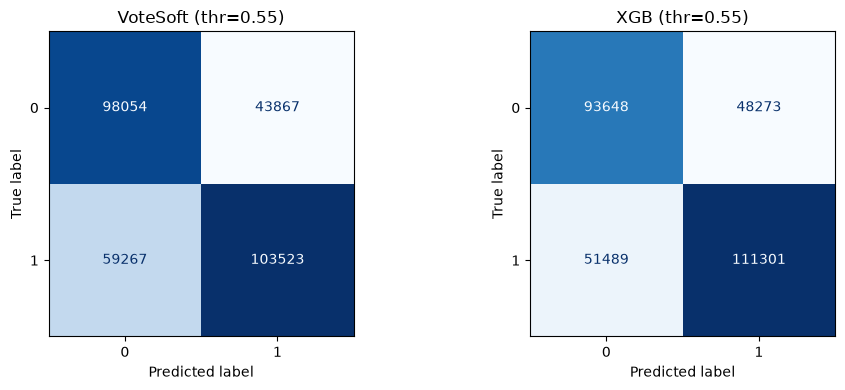

In [17]:
# Zelle 15: Confusion Matrix – VoteSoft vs XGB (gleicher Threshold)
threshold = 0.55

cm_vote = modeling.confusion_for_model(
    model_name="VoteSoft",
    k=best_k,
    threshold=threshold,
    models=models,
    log_prices=log_prices,
    all_days=all_days,
    test_days=test_days,
    lookback_train_days=LOOKBACK_TRAIN_DAYS,
    lookback_pair_days=LOOKBACK_PAIR_DAYS,
    top_corr_pairs=TOP_CORR_PAIRS,
    top_daily_pairs=TOP_DAILY_PAIRS,
    p_cointegration=P_COINTEGRATION,
    rebalance_every_n_days=REBALANCE_EVERY_N_DAYS,
    cache_dir=CACHE_DIR,
    rsi_w=RSI_W,
    z_w=Z_W,
    vol_w=VOL_W,
    min_train_samples=200,
    min_test_samples=50,
)

cm_xgb = modeling.confusion_for_model(
    model_name="XGB",
    k=best_k,
    threshold=threshold,
    models=models,
    log_prices=log_prices,
    all_days=all_days,
    test_days=test_days,
    lookback_train_days=LOOKBACK_TRAIN_DAYS,
    lookback_pair_days=LOOKBACK_PAIR_DAYS,
    top_corr_pairs=TOP_CORR_PAIRS,
    top_daily_pairs=TOP_DAILY_PAIRS,
    p_cointegration=P_COINTEGRATION,
    rebalance_every_n_days=REBALANCE_EVERY_N_DAYS,
    cache_dir=CACHE_DIR,
    rsi_w=RSI_W,
    z_w=Z_W,
    vol_w=VOL_W,
    min_train_samples=200,
    min_test_samples=50,
)

modeling.plot_confusion_matrices_side_by_side(
    cm_left=cm_vote,
    cm_right=cm_xgb,
    title_left=f"VoteSoft (thr={threshold})",
    title_right=f"XGB (thr={threshold})",
)

Bei identischem Entscheidungsschwellenwert zeigt XGBoost eine höhere Sensitivität für positive Klassen, während das Voting-Ensemble konservativer agiert. Diese Unterschiede verdeutlichen die unterschiedliche Charakteristik der Modelle bei der finalen Klassifikationsentscheidung.

<h2 id="56">5.6. Trading-Inspektion</h2>

In diesem Abschnitt wird das Modellverhalten aus einer tradingnahen Perspektive untersucht. Ziel ist keine Performance-Optimierung oder Strategieentwicklung, sondern eine Plausibilitätsprüfung der modellbasierten Signale anhand aggregierter PnL- und Risikoindikatoren.

Die Trading-Inspektion ist ausdrücklich kein vollständiger Backtest: es fehlen u. a. Slippage, Positionsgrößen-/Kapitalmodellierung, Portfolioaggregation sowie ein konsistentes Risiko- und Execution-Setup.

,day,pnl,n_trades,hit_rate,equity,drawdown
0,2025-11-21 00:00:00+00:00,0.080213,1051,0.497409,0.080213,0.000000
1,2025-11-24 00:00:00+00:00,-0.053423,1041,0.482383,0.026790,-0.053423
2,2025-11-25 00:00:00+00:00,0.063022,1032,0.495337,0.089812,0.000000
3,2025-11-26 00:00:00+00:00,0.174989,868,0.520207,0.264801,0.000000
4,2025-12-01 00:00:00+00:00,0.110521,938,0.517617,0.375322,0.000000


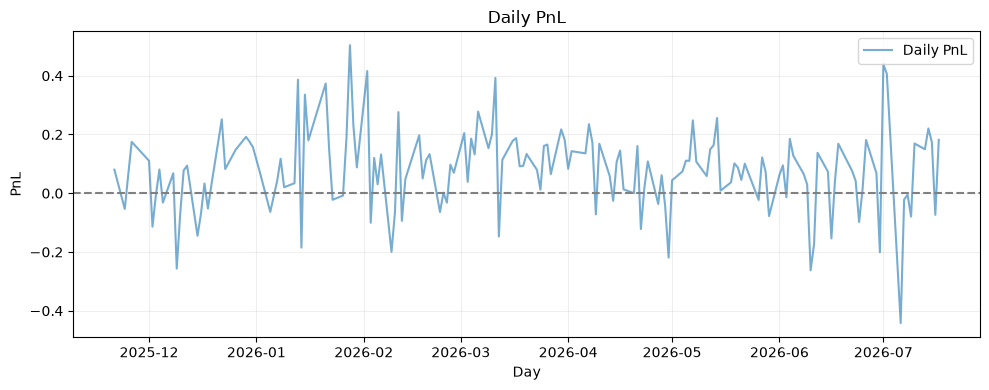

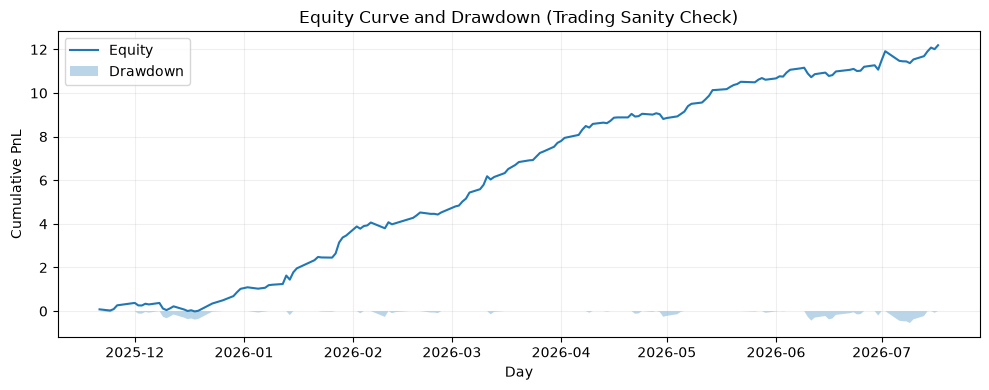

In [18]:
# Zelle 16: Trading-Inspektion – Daily PnL (kein Backtest)
MODEL_FOR_TRADING = "XGB"
THRESHOLD = 0.55
TCOST_BP = 0

trade_df = modeling.walk_forward_collect_trading_artifacts(
    model_name=MODEL_FOR_TRADING,
    k=best_k,
    models=models,
    log_prices=log_prices,
    all_days=all_days,
    test_days=test_days,
    lookback_train_days=LOOKBACK_TRAIN_DAYS,
    lookback_pair_days=LOOKBACK_PAIR_DAYS,
    top_corr_pairs=TOP_CORR_PAIRS,
    top_daily_pairs=TOP_DAILY_PAIRS,
    p_cointegration=P_COINTEGRATION,
    rebalance_every_n_days=REBALANCE_EVERY_N_DAYS,
    cache_dir=CACHE_DIR,
    rsi_w=RSI_W,
    z_w=Z_W,
    vol_w=VOL_W,
    min_train_samples=200,
    min_test_samples=50,
)

trades = trade_df.copy()

trades["enter"] = trades["proba"] > THRESHOLD
trades["direction"] = np.where(trades["z"] > 0, -1, 1)

trades["gross_pnl"] = trades["direction"] * trades["spread_ret_k"]
trades["cost"] = TCOST_BP / 1e4
trades["net_pnl"] = np.where(
    trades["enter"],
    trades["gross_pnl"] - trades["cost"],
    0.0,
)

daily = (
    trades.groupby("day")
    .agg(
        pnl=("net_pnl", "sum"),
        n_trades=("enter", "sum"),
        hit_rate=("gross_pnl", lambda x: (x > 0).mean()),
    )
    .reset_index()
)

daily["equity"] = daily["pnl"].cumsum()
daily["drawdown"] = daily["equity"] - daily["equity"].cummax()

display(daily.head())

modeling.plot_daily_pnl(daily)

modeling.plot_equity_and_drawdown(daily)

Der dargestellte PnL sowie die Equity-Kurve sind in relativen Spread-Erträgen (log-Preis-Einheiten) angegeben und dienen ausschließlich der qualitativen Beurteilung des Modellverhaltens. Es handelt sich nicht um monetäre Gewinne oder Verluste.

**Hinweis zu früheren Versionen dieser Analyse:** Diese Sektion enthielt mehrere zusammenhängende Fehler, die schrittweise gefunden und behoben wurden:

1. **Vorzeichenfehler (behoben, dann als unvollständig erkannt):** `spread_ret_k` war ursprünglich als `z_now - z_fut` definiert statt `z_fut - z_now`, wodurch eine korrekt vorhergesagte Mean-Reversion fälschlich als Verlust verbucht wurde.
2. **Tieferliegendes Problem, Z-Score statt Spread als PnL-Masseinheit:** Auch mit korrigiertem Vorzeichen war `spread_ret_k` weiterhin aus der Differenz zweier **Z-Scores** berechnet, nicht aus dem rohen Spread. Ein Z-Score ist durch seine rollierende Normierung mechanisch "mean-reverting", unabhängig davon, ob der zugrunde liegende Spread real konvergiert. Eine Kontrollrechnung auf zwei vollständig unabhängigen Random Walks (keine echte Beziehung) zeigte, dass `direction * (z_fut - z_now)` fast immer einen positiven "Gewinn" anzeigt, während `direction * (spread_fut - spread_now)` (rohe Einheiten) ein realistisches, durchmischtes Bild zeigt. `spread_ret_k` wird jetzt aus dem rohen Spread (log-Preis-Differenz) berechnet.
3. **Look-ahead im Hedge-Ratio:** Der Hedge-Ratio (`beta`) je Paar wurde für den Testtag separat auf dem isolierten Testtag gefittet, das liess Information aus dem gesamten Testtag (auch zukünftige Minuten) in die Spread-Definition einfliessen. `beta` wird jetzt ausschliesslich auf dem Trainingsfenster gefittet und für Training und Test gemeinsam verwendet.
4. **Zeilen-Fehlzuordnung:** Die Werte `z` und `spread_ret_k` wurden ursprünglich separat aus dem breiten Feature-Panel via `.stack()` rekonstruiert, mit einer anderen Zeilenreihenfolge als `X_test`/`proba`. Dadurch wurden `z`/`spread_ret_k` teils falschen (Zeitpunkt, Paar)-Kombinationen zugeordnet. Beide Werte kommen jetzt direkt und zeilengenau ausgerichtet aus derselben Stelle wie `X`/`y`.

**Ergebnis nach allen Korrekturen** (siehe Tabelle und Diagramme oben): Die Equity-Kurve zeigt nun auch echte Rückschläge und einen plausiblen Drawdown, statt monoton zu steigen wie vor der Korrektur. Die tägliche Trefferquote bewegt sich in einem realistischen, durchmischten Bereich statt in einer verdächtig engen, durchgehend hohen Bandbreite. Das passt zu einem Modell mit solider, aber nicht perfekter Vorhersagegüte (siehe ROC-Vergleich in 5.5), nicht zu einem durchgehend verlustfreien oder perfekten Ergebnis.

Der Vergleich zwischen Modellperformance und Trading-Inspektion bleibt relevant: eine hohe Vorhersagegüte (AUC) übersetzt sich nicht automatisch in ein vollständiges Handelssystem, dafür fehlen weiterhin eine explizite Positionsgrössensteuerung, ein abgestimmtes Threshold-Management, realistische Transaktionskosten sowie ein konsistentes Risikomanagement.


<h2 id="57">5.7. Export für Backtest</h2>

Die Walk-Forward-Artefakte (`trade_df`: Tag, Zeitpunkt, Paar, Z-Score, Modell-Wahrscheinlichkeit, k-Schritt-Spread-Rendite) sowie die zugehörigen Konfigurationsparameter werden gespeichert. Die nachfolgende Backtest-Analyse (Position Sizing, Portfolio-Aggregation, Performance-Kennzahlen) kann diese Datei laden, statt die rechenintensive Walk-Forward-Schleife erneut auszuführen. Der Export umfasst den vollen Zeitraum inkl. Tuning-/Holdout-Grenze (siehe 5.3.1), damit das Backtest-Notebook denselben Split konsistent weiterverwenden kann.

In [19]:
# Zelle 17: Export für Backtest-Notebook
export_meta = {
    "model_name": MODEL_FOR_TRADING,
    "best_k": best_k,
    "threshold": THRESHOLD,
    "rsi_w": RSI_W,
    "z_w": Z_W,
    "vol_w": VOL_W,
    "holdout_days_n": HOLDOUT_DAYS,
    "tuning_days_start": str(tuning_days.min().date()),
    "tuning_days_end": str(tuning_days.max().date()),
    "holdout_days_start": str(holdout_days.min().date()),
    "holdout_days_end": str(holdout_days.max().date()),
}

io.save_preprocessed_data(
    trade_df,
    data_dir="data",
    basename="trade_df_XGB",
    metadata=export_meta,
)


[Preprocessed Data (to be saved)]
Shape: (304711, 7)
Spalten: ['day', 'datetime', 'pair', 'z', 'proba', 'spread_ret_k', 'spread']

Head:
                        day                  datetime     pair         z  \
0 2025-11-21 00:00:00+00:00 2025-11-21 14:30:00+00:00  BAC_WFC -2.381921   
1 2025-11-21 00:00:00+00:00 2025-11-21 14:31:00+00:00  BAC_WFC -0.372144   
2 2025-11-21 00:00:00+00:00 2025-11-21 14:32:00+00:00  BAC_WFC  0.603710   
3 2025-11-21 00:00:00+00:00 2025-11-21 14:33:00+00:00  BAC_WFC  2.063400   
4 2025-11-21 00:00:00+00:00 2025-11-21 14:34:00+00:00  BAC_WFC  2.817146   

      proba  spread_ret_k    spread  
0  0.885723      0.007883 -1.100984  
1  0.415484      0.005333 -1.098141  
2  0.477070      0.004373 -1.096795  
3  0.809302      0.004551 -1.094699  
4  0.911002      0.002712 -1.093313  
Metadata gespeichert als data/trade_df_XGB_metadata.json

Gespeichert als data/trade_df_XGB.parquet


---

<div style="display: flex; justify-content: space-between; margin-top: 30px;">
  <a href="04_Explorative_Datenanalyse.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Zurück
    </button>
  </a>
  <a href="06_Backtest.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Weiter
    </button>
  </a>
</div>